In [1]:
# NIM: 202531086
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
print("NIM: 202531086")

NIM: 202531086


In [2]:
# NIM: 202531086
df = pd.read_csv('02_diabetes.csv')
print(df.shape)
df.info()
print("NIM: 202531086")
df.head()

(100000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
NIM: 202531086


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Duplikat: 3854
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64
                        count        mean        std    min     25%     50%  \
age                  100000.0   41.885856  22.516840   0.08   24.00   43.00   
hypertension         100000.0    0.074850   0.263150   0.00    0.00    0.00   
heart_disease        100000.0    0.039420   0.194593   0.00    0.00    0.00   
bmi                  100000.0   27.320767   6.636783  10.01   23.63   27.32   
HbA1c_level          100000.0    5.527507   1.070672   3.50    4.80    5.80   
blood_glucose_level  100000.0  138.058060  40.708136  80.00  100.00  140.00   
diabetes             100000.0    0.085000   0.278883   0.00    0.00    0.00   

                        75%     max  
age         

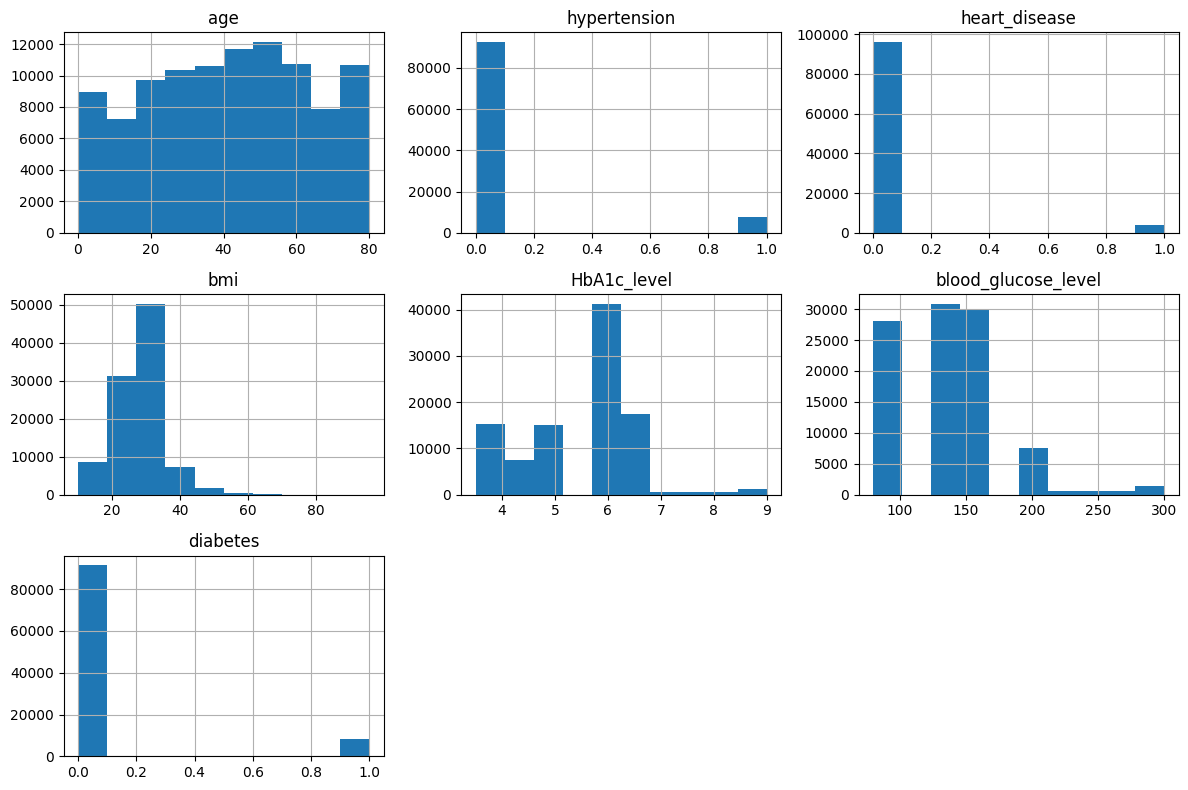

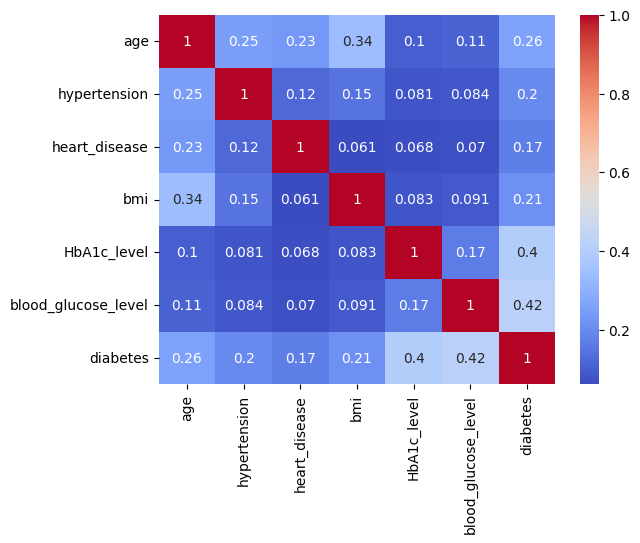

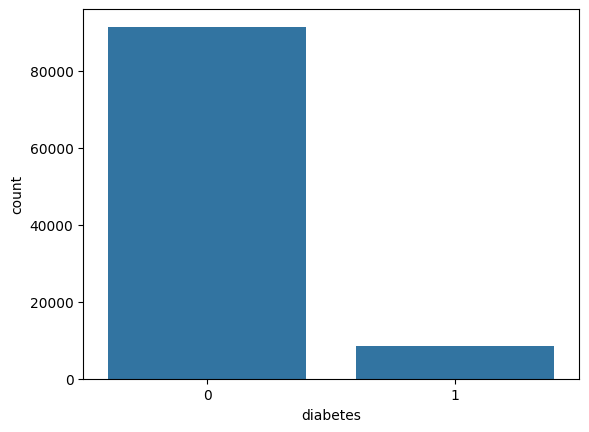

NIM: 202531086


In [3]:
# NIM: 202531086
print(df.isnull().sum())
print("Duplikat:", df.duplicated().sum())
print(df['diabetes'].value_counts(normalize=True))
print(df.describe().T)

df.hist(figsize=(12,8)); plt.tight_layout(); plt.show()
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm'); plt.show()
sns.countplot(x='diabetes', data=df); plt.show()
print("NIM: 202531086")

In [4]:
# NIM: 202531086
df = df.drop_duplicates()
df = df[df['gender'] != 'Other']
df = pd.get_dummies(df, columns=['gender','smoking_history'], drop_first=True)
print(df.shape)
print("NIM: 202531086")

(96128, 13)
NIM: 202531086


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# NIM: 202531086
X = df.drop('diabetes', axis=1); y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)
print("NIM: 202531086")

(76902, 12) (19226, 12)
NIM: 202531086


In [7]:
# NIM: 202531086
for k in [3,5,7,9,11]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    print(k, "train:", round(m.score(X_train_s,y_train),4), "test:", round(m.score(X_test_s,y_test),4))
print("NIM: 202531086")

3 train: 0.9733 test: 0.9565
5 train: 0.9684 test: 0.9582
7 train: 0.9662 test: 0.9589
9 train: 0.9644 test: 0.9595
11 train: 0.9636 test: 0.959
NIM: 202531086


Akurasi: 0.959533964423177
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     17530
           1       0.92      0.59      0.72      1696

    accuracy                           0.96     19226
   macro avg       0.94      0.79      0.85     19226
weighted avg       0.96      0.96      0.96     19226



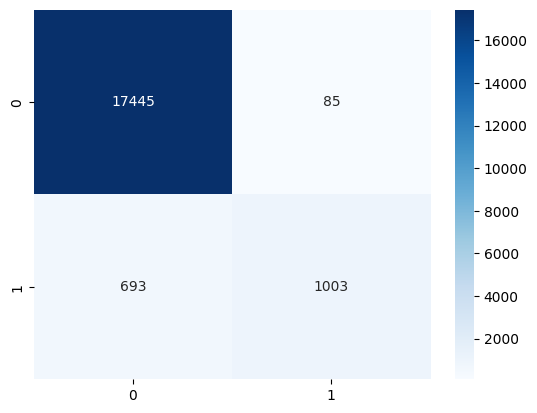

NIM: 202531086


In [8]:
# NIM: 202531086
knn = KNeighborsClassifier(n_neighbors=9).fit(X_train_s, y_train)
pred = knn.predict(X_test_s)
print("Akurasi:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues'); plt.show()
print("NIM: 202531086")

MAE : 30.69716457042015
RMSE: 37.01003230240583
R2  : 0.18062584834409412


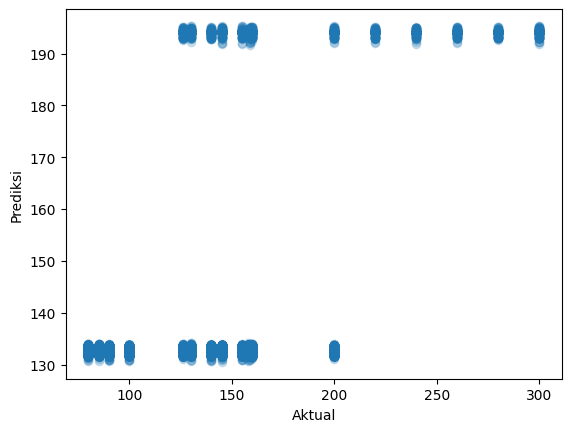

NIM: 202531086


In [9]:
# NIM: 202531086
Xr = df.drop('blood_glucose_level', axis=1); yr = df['blood_glucose_level']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
lr = LinearRegression().fit(Xr_tr, yr_tr)
p = lr.predict(Xr_te)
print("MAE :", mean_absolute_error(yr_te, p))
print("RMSE:", np.sqrt(mean_squared_error(yr_te, p)))
print("R2  :", r2_score(yr_te, p))
plt.scatter(yr_te, p, alpha=0.2); plt.xlabel('Aktual'); plt.ylabel('Prediksi'); plt.show()
print("NIM: 202531086")

In [10]:
   # NIM: 202531086
   koef = pd.Series(lr.coef_, index=Xr.columns).round(2)
   print("Intercept:", round(lr.intercept_, 2))
   print(koef)
   print("NIM: 202531086")

Intercept: 133.41
age                             0.00
hypertension                    0.20
heart_disease                  -1.08
bmi                            -0.01
HbA1c_level                    -0.10
diabetes                       61.41
gender_Male                     0.09
smoking_history_current         0.71
smoking_history_ever           -1.08
smoking_history_former         -0.14
smoking_history_never          -0.09
smoking_history_not current     0.19
dtype: float64
NIM: 202531086
